In [2]:
import numpy as np
from qiskit.quantum_info import partial_trace, entropy
from qiskit.quantum_info import Statevector

# Photon operators (3-level truncation)
a = np.array([[0,1,0],
              [0,0,np.sqrt(2)],
              [0,0,0]])   # annihilation
adag = a.T                # creation
n_photon = adag @ a        # number operator

# Atomic operators (2-level system)
sigma_z = np.array([[1,0],[0,-1]])
sigma_plus = np.array([[0,1],[0,0]])
sigma_minus = np.array([[0,0],[1,0]])



In [3]:
from numpy import kron

# Identity operators
I3 = np.eye(3)   # photon identity
I2 = np.eye(2)   # atom identity
I6 = np.eye(6)   # site identity

# Site operators
a_site = kron(a, I2)
adag_site = kron(adag, I2)
n_site = kron(n_photon, I2)

sigma_z_site = kron(I3, sigma_z)
sigma_plus_site = kron(I3, sigma_plus)
sigma_minus_site = kron(I3, sigma_minus)

# Operators for site 1 and site 2
a1 = kron(a_site, I6)
a2 = kron(I6, a_site)

sigma_z1 = kron(sigma_z_site, I6)
sigma_z2 = kron(I6, sigma_z_site)

# Build the spin-ladder operators for each site
sigma_minus1 = kron(sigma_minus_site, I6)
sigma_plus1 = kron(sigma_plus_site, I6)
sigma_minus2 = kron(I6, sigma_minus_site)
sigma_plus2 = kron(I6, sigma_plus_site)

# Parameters
wc = 1.0   # cavity frequency
wa = 1.0   # atom frequency
g  = 0.1   # coupling
J  = 0.05  # hopping

# JC Hamiltonian for each site
H_JC1 = wc * (a1.T @ a1) + (wa/2)*sigma_z1 + g*(a1.T @ sigma_minus1 + a1 @ sigma_plus1)
H_JC2 = wc * (a2.T @ a2) + (wa/2)*sigma_z2 + g*(a2.T @ sigma_minus2 + a2 @ sigma_plus2)

# Hopping term
H_hop = -J * (a1.T @ a2 + a2.T @ a1)

# Total Hamiltonian
H = H_JC1 + H_JC2 + H_hop


eigvals, eigvecs = np.linalg.eigh(H)
ground_state = eigvecs[:, 0]   # lowest energy eigenvector
ground_state = ground_state / np.linalg.norm(ground_state)

# two sites, each of dimension 6
psi = Statevector(ground_state, dims=[6, 6])

# ground_state = eigvecs[:,0]   # lowest energy eigenvector
# psi = Statevector(ground_state)


rho_site1 = partial_trace(psi, [1])   # trace out site 2
S = entropy(rho_site1, base=2)        # von Neumann entropy
print("Entanglement entropy:", S)


Entanglement entropy: 2.3982172385516484e-29


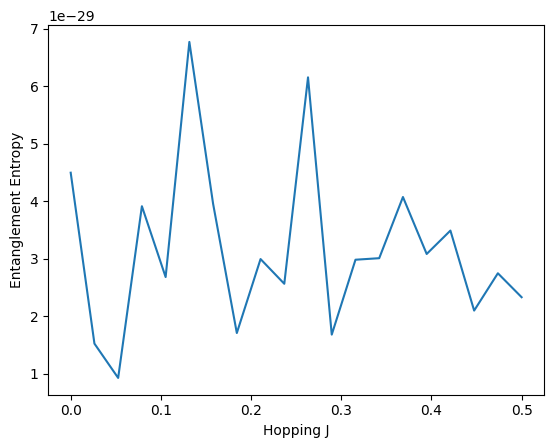

In [4]:
import matplotlib.pyplot as plt

J_values = np.linspace(0,0.5,20)
entropies = []



for J in J_values:
    H = H_JC1 + H_JC2 - J*(a1.T @ a2 + a2.T @ a1)
    eigvals, eigvecs = np.linalg.eigh(H)
    ground_state = eigvecs[:, 0]   # lowest energy eigenvector
    ground_state = ground_state / np.linalg.norm(ground_state)

    # two sites, each of dimension 6
    psi = Statevector(ground_state, dims=[6, 6])
    
    rho_site1 = partial_trace(psi, [1])
    entropies.append(entropy(rho_site1, base=2))

plt.plot(J_values, entropies)
plt.xlabel("Hopping J")
plt.ylabel("Entanglement Entropy")
plt.show()


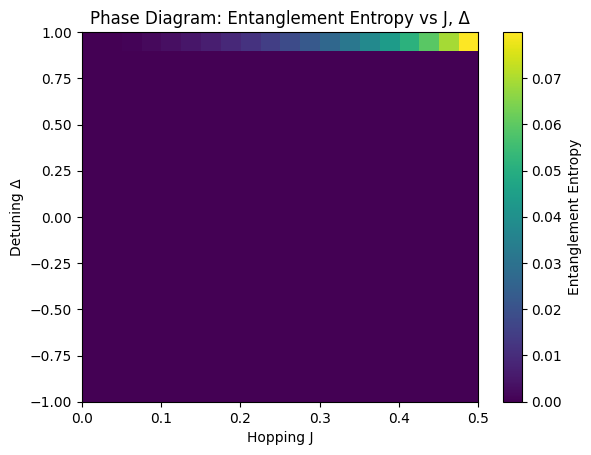

In [5]:

# Define photon + atom operators (truncated)
# ... (same as before for a, adag, sigma_z, sigma_plus, sigma_minus)

# Build site operators with kron
# ... (same as before for a1, a2, sigma_z1, sigma_z2, etc.)

def build_H(J, wc, wa, g):
    # JC Hamiltonians
    H_JC1 = wc*(a1.T@a1) + (wa/2)*sigma_z1 + g*(a1.T@sigma_minus1 + a1@sigma_plus1)
    H_JC2 = wc*(a2.T@a2) + (wa/2)*sigma_z2 + g*(a2.T@sigma_minus2 + a2@sigma_plus2)
    H_hop = -J*(a1.T@a2 + a2.T@a1)
    return H_JC1 + H_JC2 + H_hop

# Parameter sweeps
J_values = np.linspace(0,0.5,20)
Delta_values = np.linspace(-1,1,20)
wc = 1.0
g = 0.1

entropy_map = np.zeros((len(J_values), len(Delta_values)))

for i,J in enumerate(J_values):
    for j,Delta in enumerate(Delta_values):
        wa = wc - Delta
        H = build_H(J, wc, wa, g)
        eigvals, eigvecs = np.linalg.eigh(H)
        ground_state = eigvecs[:, 0]   # lowest energy eigenvector
        ground_state = ground_state / np.linalg.norm(ground_state)
        
        # two sites, each of dimension 6
        psi = Statevector(ground_state, dims=[6, 6])
        rho_site1 = partial_trace(psi, [1])
        entropy_map[i,j] = entropy(rho_site1, base=2)

# Plot heatmap
plt.imshow(entropy_map.T, origin='lower',
           extent=[J_values[0], J_values[-1], Delta_values[0], Delta_values[-1]],
           aspect='auto', cmap='viridis')
plt.colorbar(label="Entanglement Entropy")
plt.xlabel("Hopping J")
plt.ylabel("Detuning Δ")
plt.title("Phase Diagram: Entanglement Entropy vs J, Δ")
plt.show()


FOR 4 SITE 
4 sites: 6^4 = 1296states

In [6]:
# Need to correct 
import numpy as np
from qiskit.quantum_info import Statevector, partial_trace, entropy

# Define photon + atom operators (same as before)
# a, adag, sigma_z, sigma_plus, sigma_minus

# Build site operators
def site_operator(op_photon, op_atom, site, total_sites=4):
    # local site dimension = 6
    local_op = np.kron(op_photon, op_atom)
    ops = [np.eye(6) for _ in range(total_sites)]
    ops[site] = local_op
    result = ops[0]
    for i in range(1,total_sites):
        result = np.kron(result, ops[i])
    return result

# Example: photon annihilation on site 0
a1 = site_operator(a, np.eye(2), site=0)
a2 = site_operator(a, np.eye(2), site=1)
a3 = site_operator(a, np.eye(2), site=2)
a4 = site_operator(a, np.eye(2), site=3)

# Similarly build sigma_z, sigma_plus, sigma_minus for each site

# Build Hamiltonian
def build_H(J, wc, wa, g):
    H = np.zeros((1296,1296))
    for site in range(4):
        # JC Hamiltonian for each site
        a_i = [a1,a2,a3,a4][site]
        adag_i = a_i.T
        sigma_z_i = [sigma_z1,sigma_z2,sigma_z3,sigma_z4][site]
        sigma_plus_i = [sigma_plus1,sigma_plus2,sigma_plus3,sigma_plus4][site]
        sigma_minus_i = [sigma_minus1,sigma_minus2,sigma_minus3,sigma_minus4][site]
        H += wc*(adag_i@a_i) + (wa/2)*sigma_z_i + g*(adag_i@sigma_minus_i + a_i@sigma_plus_i)
    # Hopping terms (chain)
    H += -J*(a1.T@a2 + a2.T@a1 + a2.T@a3 + a3.T@a2 + a3.T@a4 + a4.T@a3)
    return H

# Diagonalize
eigvals, eigvecs = np.linalg.eigh(build_H(J=0.05, wc=1.0, wa=1.0, g=0.1))
psi = Statevector(eigvecs[:,0])

# Entropy: partition sites (1,2) vs (3,4)
rho_half = partial_trace(psi, [2,3])   # trace out sites 3 and 4
S = entropy(rho_half, base=2)
print("Entanglement entropy:", S)


NameError: name 'sigma_z3' is not defined